In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
df=pd.read_csv(r"C:\Users\Yadnit\Documents\AlmaBetter\ML Project\glassdoor_jobs.csv")
df.shape

(956, 15)

# Basic Exploration

In [4]:
df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),-1
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,Security Services,Business Services,$100 to $500 million (USD),-1
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),"Oak Ridge National Laboratory, National Renewa..."
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"


In [5]:
df.columns

Index(['Unnamed: 0', 'Job Title', 'Salary Estimate', 'Job Description',
       'Rating', 'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors'],
      dtype='object')

In [6]:
df.info

<bound method DataFrame.info of      Unnamed: 0                                          Job Title  \
0             0                                     Data Scientist   
1             1                          Healthcare Data Scientist   
2             2                                     Data Scientist   
3             3                                     Data Scientist   
4             4                                     Data Scientist   
..          ...                                                ...   
951         951                               Senior Data Engineer   
952         952  Project Scientist - Auton Lab, Robotics Institute   
953         953                               Data Science Manager   
954         954                                      Data Engineer   
955         955          Research Scientist – Security and Privacy   

                 Salary Estimate  \
0     $53K-$91K (Glassdoor est.)   
1    $63K-$112K (Glassdoor est.)   
2     $80K-$90K (Gl

In [7]:
df.describe()

,Unnamed: 0,Rating,Founded
count,956.000000,956.000000,956.000000
mean,477.500000,3.601255,1774.605649
std,276.117729,1.067619,598.942517
min,0.000000,-1.000000,-1.000000
25%,238.750000,3.300000,1937.000000
50%,477.500000,3.800000,1992.000000
75%,716.250000,4.200000,2008.000000
max,955.000000,5.000000,2019.000000


# Check missing values and duplicates

In [8]:
print(df.isnull().sum())

Unnamed: 0           0
Job Title            0
Salary Estimate      0
Job Description      0
Rating               0
Company Name         0
Location             0
Headquarters         0
Size                 0
Founded              0
Type of ownership    0
Industry             0
Sector               0
Revenue              0
Competitors          0
dtype: int64


In [9]:
print((df.isnull().sum() / len(df)) * 100)

Unnamed: 0           0.0
Job Title            0.0
Salary Estimate      0.0
Job Description      0.0
Rating               0.0
Company Name         0.0
Location             0.0
Headquarters         0.0
Size                 0.0
Founded              0.0
Type of ownership    0.0
Industry             0.0
Sector               0.0
Revenue              0.0
Competitors          0.0
dtype: float64


In [10]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


# DATA CLEANING

In [11]:
df.drop(columns=['Unnamed: 0'], inplace=True) #removing unnamed Columns


In [12]:
df.shape

(956, 14)

In [13]:
df.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),-1
1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1
2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,Security Services,Business Services,$100 to $500 million (USD),-1
3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),"Oak Ridge National Laboratory, National Renewa..."
4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"


# Cleaning Salary Column

In [14]:
df['Salary Estimate'].unique()[:20]

array(['$53K-$91K (Glassdoor est.)', '$63K-$112K (Glassdoor est.)',
       '$80K-$90K (Glassdoor est.)', '$56K-$97K (Glassdoor est.)',
       '$86K-$143K (Glassdoor est.)', '$71K-$119K (Glassdoor est.)',
       '$54K-$93K (Glassdoor est.)', '$86K-$142K (Glassdoor est.)',
       '$38K-$84K (Glassdoor est.)', '$120K-$160K (Glassdoor est.)',
       '$126K-$201K (Glassdoor est.)', '$64K-$106K (Glassdoor est.)',
       '$106K-$172K (Glassdoor est.)', '$46K-$85K (Glassdoor est.)',
       '$83K-$144K (Glassdoor est.)', '$102K-$190K (Glassdoor est.)',
       '$67K-$137K (Glassdoor est.)', '$118K-$189K (Glassdoor est.)',
       '$110K-$175K (Glassdoor est.)', '$64K-$111K (Glassdoor est.)'],
      dtype=object)

In [15]:
df['Salary Estimate'].dtype

dtype('O')

In [16]:
df['Salary_Clean']=df['Salary Estimate'].copy()

In [17]:
df.shape

(956, 15)

In [18]:
df[['Salary Estimate', 'Salary_Clean']].head()

,Salary Estimate,Salary_Clean
0,$53K-$91K (Glassdoor est.),$53K-$91K (Glassdoor est.)
1,$63K-$112K (Glassdoor est.),$63K-$112K (Glassdoor est.)
2,$80K-$90K (Glassdoor est.),$80K-$90K (Glassdoor est.)
3,$56K-$97K (Glassdoor est.),$56K-$97K (Glassdoor est.)
4,$86K-$143K (Glassdoor est.),$86K-$143K (Glassdoor est.)


In [19]:
print("Hourly Salary Records:")
display(
    df[df['Salary Estimate'].str.contains(
        'Per Hour', case=False, na=False
    )]['Salary Estimate'].head(10)
)

print("Unavailable Salary Records:")
display(
    df[df['Salary Estimate'] == '-1']['Salary Estimate'].value_counts()
)


Hourly Salary Records:


197    $17-$24 Per Hour(Glassdoor est.)
209    $21-$34 Per Hour(Glassdoor est.)
240    $18-$25 Per Hour(Glassdoor est.)
247    $21-$34 Per Hour(Glassdoor est.)
257    $15-$25 Per Hour(Glassdoor est.)
307    $17-$24 Per Hour(Glassdoor est.)
337    $21-$34 Per Hour(Glassdoor est.)
427    $18-$25 Per Hour(Glassdoor est.)
437    $24-$39 Per Hour(Glassdoor est.)
456    $21-$34 Per Hour(Glassdoor est.)
Name: Salary Estimate, dtype: object

Unavailable Salary Records:


Salary Estimate
-1    214
Name: count, dtype: int64

In [20]:
df['Salary Estimate'].str.contains('Per Hour')

0      False
1      False
2      False
3      False
4      False
       ...  
951    False
952    False
953    False
954    False
955    False
Name: Salary Estimate, Length: 956, dtype: bool

In [21]:
# Remove Glassdoor estimation text

df['Salary_Clean'] = df['Salary_Clean'].str.replace(
    '(Glassdoor est.)', '', regex=False
)

# Display results
df[['Salary Estimate', 'Salary_Clean']].head()

,Salary Estimate,Salary_Clean
0,$53K-$91K (Glassdoor est.),$53K-$91K
1,$63K-$112K (Glassdoor est.),$63K-$112K
2,$80K-$90K (Glassdoor est.),$80K-$90K
3,$56K-$97K (Glassdoor est.),$56K-$97K
4,$86K-$143K (Glassdoor est.),$86K-$143K


In [22]:
df['Salary_Clean'] = df['Salary_Clean'].str.replace('$', '', regex=False)

df['Salary_Clean'] = df['Salary_Clean'].str.replace('K', '', regex=False)

# Display results
df[['Salary Estimate', 'Salary_Clean']].head(10)


,Salary Estimate,Salary_Clean
0,$53K-$91K (Glassdoor est.),53-91
1,$63K-$112K (Glassdoor est.),63-112
2,$80K-$90K (Glassdoor est.),80-90
3,$56K-$97K (Glassdoor est.),56-97
4,$86K-$143K (Glassdoor est.),86-143
5,$71K-$119K (Glassdoor est.),71-119
6,$54K-$93K (Glassdoor est.),54-93
7,$86K-$142K (Glassdoor est.),86-142
8,$38K-$84K (Glassdoor est.),38-84
9,$120K-$160K (Glassdoor est.),120-160


In [23]:

df['Hourly'] = df['Salary Estimate'].str.contains(
    'Per Hour',
    case=False,
    na=False
)

# Check hourly and annual salary counts

print(df['Hourly'].value_counts())


Hourly
False    932
True      24
Name: count, dtype: int64


# Minimum & MAXIMUM SALARY

In [24]:
df['Salary_Clean'] = df['Salary_Clean'].str.replace(
    'Per Hour', '', regex=False
)

df['Salary_Clean'] = df['Salary_Clean'].str.replace(
    '(Employer est.)', '', regex=False
)

# Display hourly records
display(df.loc[df['Hourly'], ['Salary Estimate', 'Salary_Clean']].head(10))


,Salary Estimate,Salary_Clean
197,$17-$24 Per Hour(Glassdoor est.),17-24
209,$21-$34 Per Hour(Glassdoor est.),21-34
240,$18-$25 Per Hour(Glassdoor est.),18-25
247,$21-$34 Per Hour(Glassdoor est.),21-34
257,$15-$25 Per Hour(Glassdoor est.),15-25
307,$17-$24 Per Hour(Glassdoor est.),17-24
337,$21-$34 Per Hour(Glassdoor est.),21-34
427,$18-$25 Per Hour(Glassdoor est.),18-25
437,$24-$39 Per Hour(Glassdoor est.),24-39
456,$21-$34 Per Hour(Glassdoor est.),21-34


In [25]:
# Extract minimum and maximum salary

df[['min_salary', 'max_salary']] = (
    df['Salary_Clean']
    .str.extract(r'(\d+)-(\d+)')
    .astype(float)
)

# Display results
df[['Salary_Clean', 'min_salary', 'max_salary']].head(10)


,Salary_Clean,min_salary,max_salary
0,53-91,53.0,91.0
1,63-112,63.0,112.0
2,80-90,80.0,90.0
3,56-97,56.0,97.0
4,86-143,86.0,143.0
5,71-119,71.0,119.0
6,54-93,54.0,93.0
7,86-142,86.0,142.0
8,38-84,38.0,84.0
9,120-160,120.0,160.0


In [26]:
# Convert hourly salary into annual salary (in thousands)

df.loc[df['Hourly'], 'min_salary'] = (
    df.loc[df['Hourly'], 'min_salary'] * 2080 / 1000
)

df.loc[df['Hourly'], 'max_salary'] = (
    df.loc[df['Hourly'], 'max_salary'] * 2080 / 1000
)

# Verify conversion
display(
    df.loc[df['Hourly'],
           ['Salary Estimate', 'min_salary', 'max_salary']].head(10)
)

,Salary Estimate,min_salary,max_salary
197,$17-$24 Per Hour(Glassdoor est.),35.36,49.92
209,$21-$34 Per Hour(Glassdoor est.),43.68,70.72
240,$18-$25 Per Hour(Glassdoor est.),37.44,52.00
247,$21-$34 Per Hour(Glassdoor est.),43.68,70.72
257,$15-$25 Per Hour(Glassdoor est.),31.20,52.00
307,$17-$24 Per Hour(Glassdoor est.),35.36,49.92
337,$21-$34 Per Hour(Glassdoor est.),43.68,70.72
427,$18-$25 Per Hour(Glassdoor est.),37.44,52.00
437,$24-$39 Per Hour(Glassdoor est.),49.92,81.12
456,$21-$34 Per Hour(Glassdoor est.),43.68,70.72


In [27]:

# Calculate average salary

df['avg_salary'] = (
    df['min_salary'] + df['max_salary']
) / 2

# Display salary columns
display(
    df[['min_salary', 'max_salary', 'avg_salary']].head(10)
)

,min_salary,max_salary,avg_salary
0,53.0,91.0,72.0
1,63.0,112.0,87.5
2,80.0,90.0,85.0
3,56.0,97.0,76.5
4,86.0,143.0,114.5
5,71.0,119.0,95.0
6,54.0,93.0,73.5
7,86.0,142.0,114.0
8,38.0,84.0,61.0
9,120.0,160.0,140.0


In [28]:
y = df['avg_salary']

# Handling Missing Salary

In [29]:
# Check missing values in target variable

print("Missing avg_salary:", df['avg_salary'].isnull().sum())

print("Total records:", len(df))

Missing avg_salary: 214
Total records: 956


In [30]:
df = df.dropna(subset=['avg_salary'])

# Verify updated dataset
print("Updated Dataset Shape:", df.shape)
print("Missing Salary:", df['avg_salary'].isnull().sum())

Updated Dataset Shape: (742, 19)
Missing Salary: 0


# Exploratory Data Analysis (EDA).

# Average Salary Distribution

In [33]:
df['avg_salary'].describe()

count    742.000000
mean     101.499326
std       37.463032
min       15.500000
25%       73.500000
50%       97.500000
75%      122.500000
max      254.000000
Name: avg_salary, dtype: float64

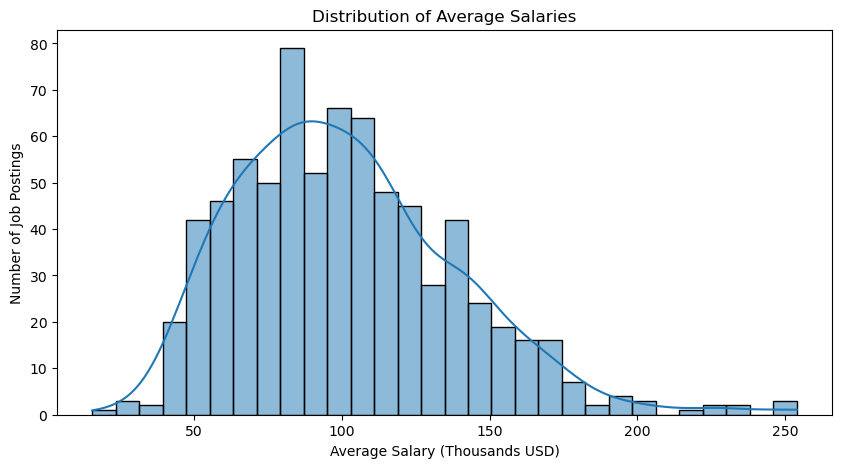

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['avg_salary'],
    bins=30,
    kde=True
)

plt.title('Distribution of Average Salaries')
plt.xlabel('Average Salary (Thousands USD)')
plt.ylabel('Number of Job Postings')

plt.show()

# Salary by Job Title

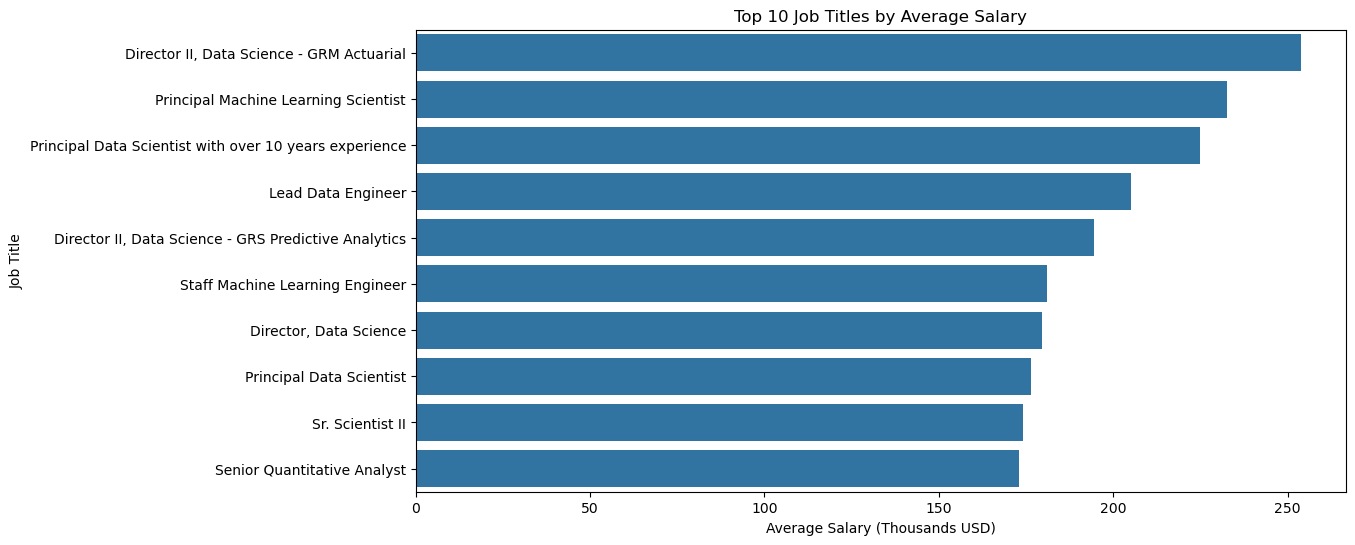

In [34]:

# Top 10 job titles by average salary

top_jobs = (
    df.groupby('Job Title')['avg_salary']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_jobs.values,
    y=top_jobs.index
)

plt.title('Top 10 Job Titles by Average Salary')
plt.xlabel('Average Salary (Thousands USD)')
plt.ylabel('Job Title')

plt.show()


# Salary by Company Size

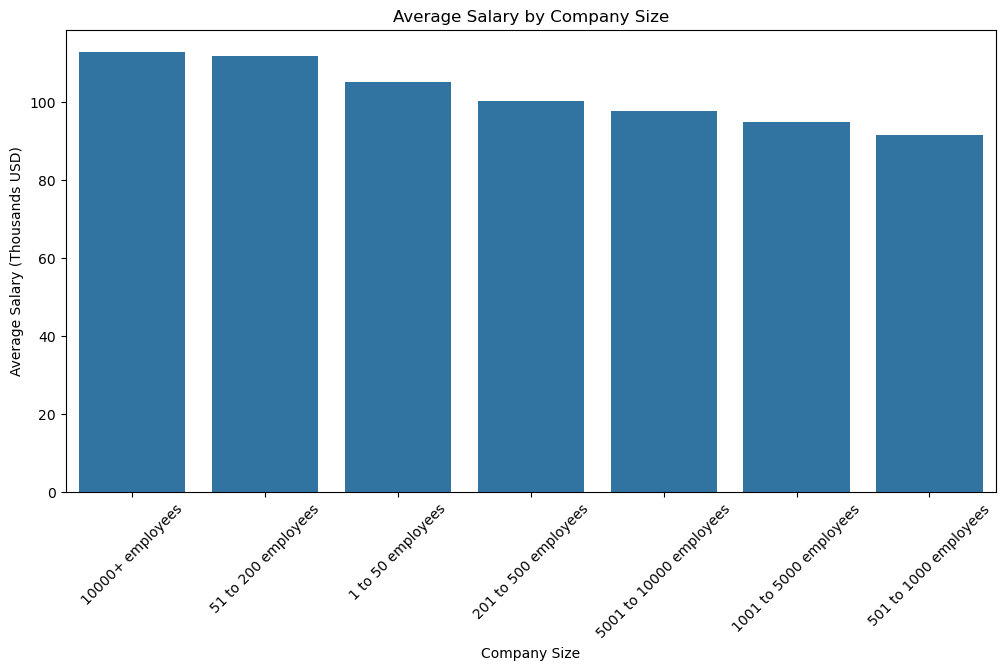

In [36]:
# Remove unavailable company size values

company_df = df[
    ~df['Size'].isin(['Unknown', '-1'])
]

# Calculate average salary by company size

company_salary = (
    company_df.groupby('Size')['avg_salary']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=company_salary.index,
    y=company_salary.values
)

plt.title('Average Salary by Company Size')
plt.xlabel('Company Size')
plt.ylabel('Average Salary (Thousands USD)')
plt.xticks(rotation=45)

plt.show()

# Salary by Location

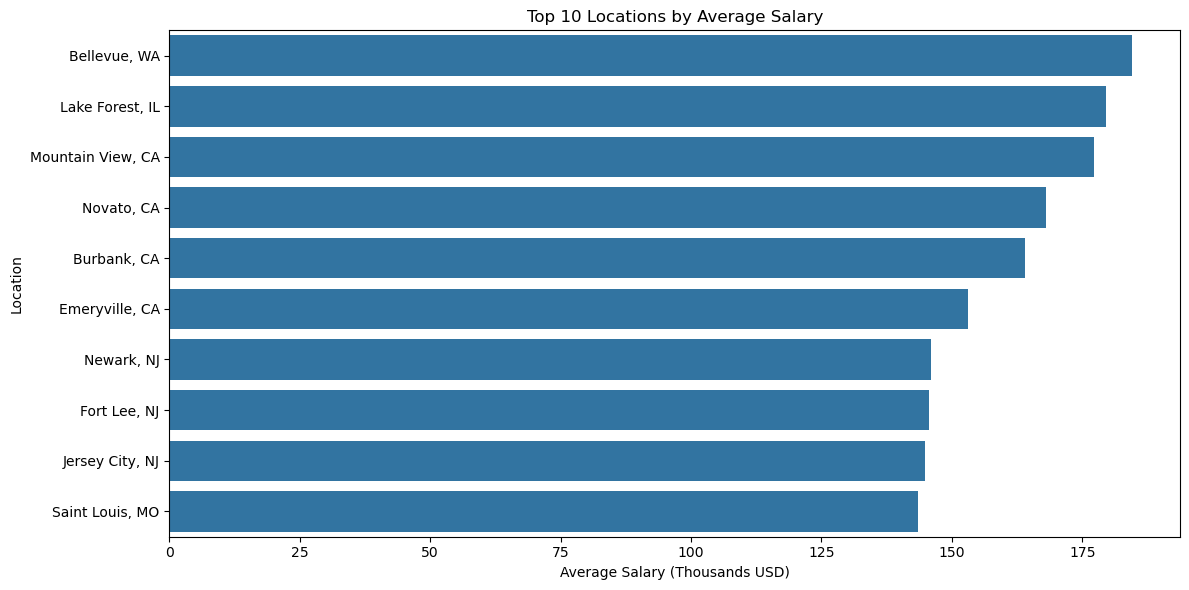

In [37]:

# Calculate average salary by location

location_salary = (
    df.groupby('Location')['avg_salary']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# Create visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    x=location_salary.values,
    y=location_salary.index
)

plt.title('Top 10 Locations by Average Salary')
plt.xlabel('Average Salary (Thousands USD)')
plt.ylabel('Location')

plt.tight_layout()
plt.show()


# Salary by Company Rating

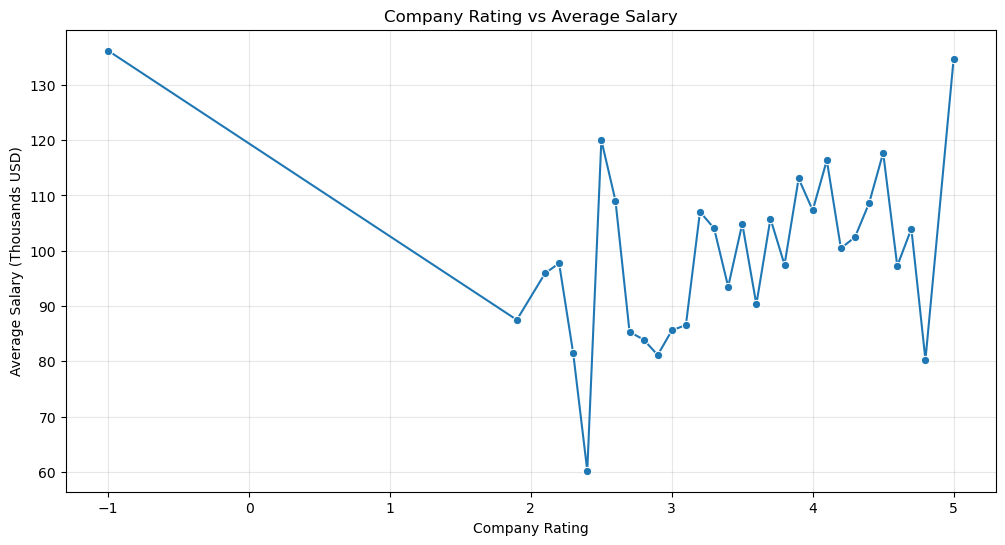

In [39]:

# Calculate average salary by company rating

rating_salary = (
    df.groupby('Rating')['avg_salary']
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=rating_salary.index,
    y=rating_salary.values,
    marker='o'
)

plt.title('Company Rating vs Average Salary')
plt.xlabel('Company Rating')
plt.ylabel('Average Salary (Thousands USD)')
plt.grid(alpha=0.3)

plt.show()


 # Correlation Analisys

In [40]:

# Select numerical columns

numeric_df = df.select_dtypes(include=np.number)

# Display numerical columns
print("Numerical Columns:")
print(numeric_df.columns.tolist())


Numerical Columns:
['Rating', 'Founded', 'min_salary', 'max_salary', 'avg_salary']


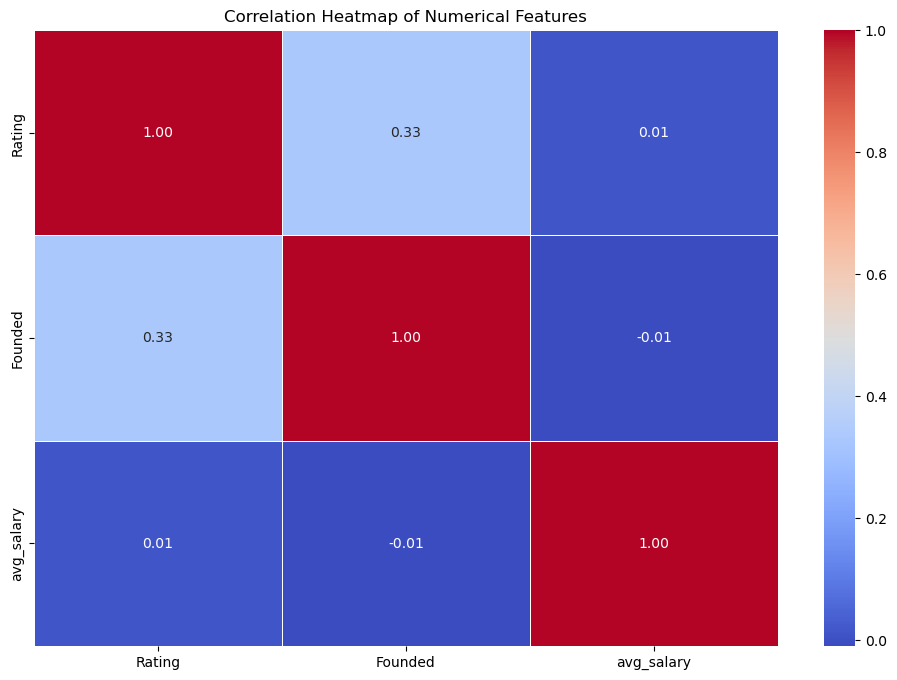

In [41]:

# Remove salary components to avoid misleading correlation

corr_df = numeric_df.drop(
    columns=['min_salary', 'max_salary'],
    errors='ignore'
)

# Calculate correlation
correlation = corr_df.corr()

# Visualize correlation
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()


# Feature Engineering


In [42]:
print(df.columns.tolist())

['Job Title', 'Salary Estimate', 'Job Description', 'Rating', 'Company Name', 'Location', 'Headquarters', 'Size', 'Founded', 'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors', 'Salary_Clean', 'Hourly', 'min_salary', 'max_salary', 'avg_salary']


In [43]:
# Check unique job titles

print("Unique Job Titles:", df['Job Title'].nunique())

# Check unique locations

print("Unique Locations:", df['Location'].nunique())

# Check unique industries

print("Unique Industries:", df['Industry'].nunique())

# Check unique company sizes

print("Unique Company Sizes:", df['Size'].nunique())

Unique Job Titles: 264
Unique Locations: 200
Unique Industries: 60
Unique Company Sizes: 9


In [44]:

# Create a function to categorize job titles

def categorize_job(title):

    title = title.lower()

    if 'data scientist' in title:
        return 'Data Scientist'

    elif 'data analyst' in title or 'business analyst' in title:
        return 'Data Analyst'

    elif 'machine learning' in title:
        return 'Machine Learning'

    elif 'data engineer' in title:
        return 'Data Engineer'

    elif 'software engineer' in title or 'developer' in title:
        return 'Software Engineer'

    elif 'manager' in title or 'director' in title:
        return 'Management'

    else:
        return 'Other'


# Apply function to Job Title column

df['Job_Role'] = df['Job Title'].apply(categorize_job)

# Check job role distribution

print(df['Job_Role'].value_counts())


Job_Role
Data Scientist       279
Other                178
Data Engineer        119
Data Analyst          99
Management            36
Machine Learning      22
Software Engineer      9
Name: count, dtype: int64


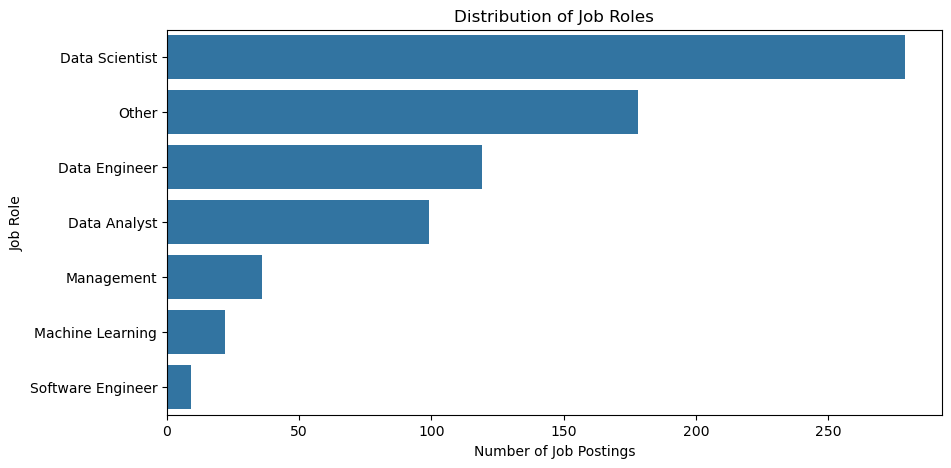

In [45]:

# Visualize job role distribution

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y='Job_Role',
    order=df['Job_Role'].value_counts().index
)

plt.title('Distribution of Job Roles')
plt.xlabel('Number of Job Postings')
plt.ylabel('Job Role')

plt.show()


# Prepare independent and dependent variables

In [46]:
y = df['avg_salary']

In [47]:

# Select candidate features

features = [
    'Job_Role',
    'Rating',
    'Location',
    'Size',
    'Founded',
    'Industry',
    'Sector',
    'Type of ownership'
]

# Check missing values
print("Missing values:")
print(df[features].isnull().sum())

# Check unavailable values
for col in features:
    print(f"\n{col}:")
    print(df[col].value_counts().head(5))


Missing values:
Job_Role             0
Rating               0
Location             0
Size                 0
Founded              0
Industry             0
Sector               0
Type of ownership    0
dtype: int64

Job_Role:
Job_Role
Data Scientist    279
Other             178
Data Engineer     119
Data Analyst       99
Management         36
Name: count, dtype: int64

Rating:
Rating
3.9    63
3.8    61
3.7    61
3.5    49
4.0    47
Name: count, dtype: int64

Location:
Location
New York, NY         55
San Francisco, CA    49
Cambridge, MA        47
Chicago, IL          32
Boston, MA           23
Name: count, dtype: int64

Size:
Size
1001 to 5000 employees    150
501 to 1000 employees     134
10000+ employees          130
201 to 500 employees      117
51 to 200 employees        94
Name: count, dtype: int64

Founded:
Founded
-1       50
 2010    32
 2008    31
 1996    27
 2006    24
Name: count, dtype: int64

Industry:
Industry
Biotech & Pharmaceuticals           112
Insurance Carriers   

In [48]:

# Replace invalid founding years with NaN

df['Founded'] = pd.to_numeric(
    df['Founded'], errors='coerce'
)

df['Founded'] = df['Founded'].replace(-1, np.nan)


# Replace invalid company ratings with NaN

df['Rating'] = pd.to_numeric(
    df['Rating'], errors='coerce'
)

df['Rating'] = df['Rating'].replace(-1, np.nan)


# Handle unavailable categorical values

categorical_cols = [
    'Job_Role',
    'Location',
    'Size',
    'Industry',
    'Sector',
    'Type of ownership'
]

df[categorical_cols] = df[categorical_cols].replace(
    ['-1', 'Unknown', ''],
    np.nan
)


# Check missing values

print("Missing Values After Cleaning:")
print(df[
    ['Rating', 'Founded'] + categorical_cols
].isnull().sum())


Missing Values After Cleaning:
Rating               11
Founded              50
Job_Role              0
Location              0
Size                 10
Industry             10
Sector               10
Type of ownership     2
dtype: int64


In [49]:

# Define independent variables (features)

X = df[
    [
        'Job_Role',
        'Rating',
        'Location',
        'Size',
        'Founded',
        'Industry',
        'Sector',
        'Type of ownership'
    ]
]

# Define dependent variable (target)

y = df['avg_salary']

# Check dimensions

print("X Shape:", X.shape)
print("y Shape:", y.shape)

# Display first five records

display(X.head())
display(y.head())


X Shape: (742, 8)
y Shape: (742,)


,Job_Role,Rating,Location,Size,Founded,Industry,Sector,Type of ownership
0,Data Scientist,3.8,"Albuquerque, NM",501 to 1000 employees,1973.0,Aerospace & Defense,Aerospace & Defense,Company - Private
1,Data Scientist,3.4,"Linthicum, MD",10000+ employees,1984.0,Health Care Services & Hospitals,Health Care,Other Organization
2,Data Scientist,4.8,"Clearwater, FL",501 to 1000 employees,2010.0,Security Services,Business Services,Company - Private
3,Data Scientist,3.8,"Richland, WA",1001 to 5000 employees,1965.0,Energy,"Oil, Gas, Energy & Utilities",Government
4,Data Scientist,2.9,"New York, NY",51 to 200 employees,1998.0,Advertising & Marketing,Business Services,Company - Private


0     72.0
1     87.5
2     85.0
3     76.5
4    114.5
Name: avg_salary, dtype: float64

# Train-Test Split

In [50]:
from sklearn.model_selection import train_test_split

In [51]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Check dataset dimensions

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (593, 8)
X_test: (149, 8)
y_train: (593,)
y_test: (149,)


In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


In [53]:

# Numerical features

numeric_features = ['Rating', 'Founded']


# Categorical features

categorical_features = [
    'Job_Role',
    'Location',
    'Size',
    'Industry',
    'Sector',
    'Type of ownership'
]


In [54]:

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])


In [55]:

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


In [56]:

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


In [57]:

# Fit preprocessing on training data and transform it

X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using training preprocessing

X_test_processed = preprocessor.transform(X_test)


# Check dimensions

print("Training Data Shape:", X_train_processed.shape)

print("Testing Data Shape:", X_test_processed.shape)


Training Data Shape: (593, 290)
Testing Data Shape: (149, 290)


# Model Building: Linear Regression

In [59]:

from sklearn.linear_model import LinearRegression


In [60]:
lr_model = LinearRegression()

In [63]:

# Train the model

lr_model.fit(X_train_processed, y_train)



,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [64]:

# Predict salaries using testing data

y_pred_lr = lr_model.predict(X_test_processed)

# Display first 10 predictions

print("Predicted Salaries:")
print(y_pred_lr[:10])

print("\nActual Salaries:")
print(y_test.iloc[:10].values)


Predicted Salaries:
[ 92.70575698  48.50910037 140.06716836 121.93125768 154.45727152
 119.13530064 177.83138669  10.19513066  75.31648991 124.10567518]

Actual Salaries:
[100.5  48.5 154.5 122.  162.  107.  150.5  44.5  59.5  51.5]


In [65]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [66]:

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred_lr)

rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2 = r2_score(y_test, y_pred_lr)

# Display results

print("Linear Regression Performance")
print("--------------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


Linear Regression Performance
--------------------------------
MAE: 18.8
RMSE: 29.77
R2 Score: 0.4348


# Random Forest

In [67]:

from sklearn.ensemble import RandomForestRegressor


In [68]:

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    n_jobs=-1
)


In [69]:
rf_model.fit(X_train_processed, y_train)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [70]:

y_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest Predictions:")
print(y_pred_rf[:10])

print("\nActual Salaries:")
print(y_test.iloc[:10].values)

Random Forest Predictions:
[124.9642595   52.30106548 142.4140643  118.22478439 139.40337884
 128.05633968 157.30720437  61.98936746  73.99780013  67.17175151]

Actual Salaries:
[100.5  48.5 154.5 122.  162.  107.  150.5  44.5  59.5  51.5]


In [71]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------")
print("MAE:", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))
print("R2 Score:", round(r2_rf, 4))


Random Forest Performance
--------------------------
MAE: 14.62
RMSE: 21.43
R2 Score: 0.7072
